# 01 — Split, Train, Evaluate

**الفكرة بسطر واحد:** منقسم الداتا حسب الشخص أو الفيديو (مو عشوائياً)، منقارن Baseline (A) مع Classifier (B) على Validation، منختار العتبة، وبعدين منجرب **مرة وحدة بس** على Test.

| المجموعة | إيجابيات (علاء) | سلبيات | ليش |
|---|---|---|---|
| Train | 6 فيديوهات | LFW (70% من الهويات) + friend1 | التدريب |
| Validation | فيديوهين محجوزين | LFW (15% من الهويات) | مقارنة A و B واختيار العتبة |
| Test | جلسة alaa_test | LFW (15% من الهويات) | الرقم النهائي، مرة وحدة |

**قاعدة:** العتبة بتنختار على Validation، مو على Test. لو اخترناها على Test بنكون عدّلنا الامتحان على مقاس الإجابات.

شغّل الخلايا بالترتيب. لازم يكون مسار الشغل (working directory) هو مجلد `face_recognition`.

In [22]:
import os, json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score

PROC = Path("data/processed")
MODELS = Path("models")
MODELS.mkdir(exist_ok=True)

SEED = 42
VAL_VIDEOS = ["alaa_laptop_04", "alaa_phone_01"]            # Alaa videos held out for validation
LFW_FRACTIONS = {"train": 0.70, "val": 0.15, "test": 0.15}  # split by IDENTITY, not by image

## 1) تحميل الداتا

كل ملف `.npz` فيه بصمات (Embeddings) ومعها مسار صورة الوجه. لما حذفنا صور من `data/review/` بالمراجعة اليدوية، البصمات بقيت بالملف. هون منحتفظ بس بالبصمات اللي صورتها لسا موجودة، يعني مراجعتك بتأثر فعلياً على التدريب.

In [23]:
def load(name):
    d = np.load(PROC / f"{name}.npz")
    keep = np.array([os.path.exists(p) for p in d["crop_paths"]])
    print(f"{name:<10} extracted={len(keep):>6}  kept after manual review={int(keep.sum()):>6}")
    return {k: d[k][keep] for k in d.files}

alaa, alaa_test, others, lfw = (load(n) for n in ["alaa", "alaa_test", "others", "lfw"])

alaa       extracted=   591  kept after manual review=   585
alaa_test  extracted=    57  kept after manual review=    56
others     extracted=    93  kept after manual review=    93
lfw        extracted= 10266  kept after manual review= 10266


## 2) التقسيم

- **إيجابيات علاء:** نقسم حسب **الفيديو**. إطارات نفس الفيديو شبه متطابقة، فلو وزعناها عشوائياً بين Train و Validation بيصير Data Leakage ودقة وهمية.
- **سلبيات LFW:** نقسم حسب **الهوية**. الغريب بالواقع شخص جديد كلياً، فلازم هويات Validation و Test ما يكونوا شافهم النموذج.
- **friend1:** بالـ Train بس (هو شخص واحد، ما منقدر نعمل منه اختبار غرباء).

In [24]:
def video_of(path):
    return Path(str(path)).name.rsplit("_f", 1)[0]

# --- Alaa positives: split by video
alaa_video = np.array([video_of(p) for p in alaa["crop_paths"]])
is_val = np.isin(alaa_video, VAL_VIDEOS)
assert is_val.any(), f"VAL_VIDEOS not found. Videos present: {sorted(set(alaa_video))}"
pos_train = alaa["embeddings"][~is_val]
pos_val = alaa["embeddings"][is_val]
pos_test = alaa_test["embeddings"]

# --- Negatives: split LFW by identity
rng = np.random.default_rng(SEED)
ids = np.unique(lfw["identities"])
rng.shuffle(ids)
n_train = int(len(ids) * LFW_FRACTIONS["train"])
n_val = int(len(ids) * LFW_FRACTIONS["val"])
split_ids = {
    "train": ids[:n_train],
    "val": ids[n_train:n_train + n_val],
    "test": ids[n_train + n_val:],
}
assert not set(split_ids["train"]) & set(split_ids["val"])
assert not set(split_ids["train"]) & set(split_ids["test"])
assert not set(split_ids["val"]) & set(split_ids["test"])

def lfw_part(part):
    return lfw["embeddings"][np.isin(lfw["identities"], split_ids[part])]

neg_train = np.vstack([lfw_part("train"), others["embeddings"]])
neg_val = lfw_part("val")
neg_test = lfw_part("test")

def make(pos, neg):
    X = np.vstack([pos, neg])
    y = np.r_[np.ones(len(pos)), np.zeros(len(neg))]
    return X, y

X_tr, y_tr = make(pos_train, neg_train)
X_va, y_va = make(pos_val, neg_val)
X_te, y_te = make(pos_test, neg_test)

print(f"{'':<12}{'positives':>10}{'negatives':>11}")
for name, p, n in [("train", pos_train, neg_train), ("validation", pos_val, neg_val), ("test", pos_test, neg_test)]:
    print(f"{name:<12}{len(p):>10}{len(n):>11}")
print(f"\nnegatives/positives in train: {len(neg_train)/len(pos_train):.1f}")

             positives  negatives
train              423       7140
validation         162       1639
test                56       1580

negatives/positives in train: 16.9


## 3) المقاييس

بأي عتبة في نوعين من الغلط:

- **FAR** (False Accept Rate) = غرباء انقبلوا ÷ كل محاولات الغرباء
- **FRR** (False Reject Rate) = علاء انرفض ÷ كل محاولات علاء
- **TAR** = 1 − FRR (نسبة علاء المقبول)

كل نسبة بتنقسم على مجموع فئتها، فعدم التوازن (585 مقابل آلاف) ما بيشوّهها. لهيك ما منستخدم Accuracy.

In [25]:
def tar_at_far(y, s, far):
    """Best TAR achievable while keeping FAR <= far. Returns (tar, achieved_far, threshold)."""
    fpr, tpr, thr = roc_curve(y, s)
    i = np.searchsorted(fpr, far, side="right") - 1
    return tpr[i], fpr[i], thr[i]

def eer(y, s):
    """Equal Error Rate: point where FAR == FRR. Returns (eer, threshold)."""
    fpr, tpr, thr = roc_curve(y, s)
    fnr = 1 - tpr
    i = int(np.nanargmin(np.abs(fpr - fnr)))
    return (fpr[i] + fnr[i]) / 2, thr[i]

def summarize(y, s):
    out = {"AUC": roc_auc_score(y, s), "EER": eer(y, s)[0]}
    for far in (0.05, 0.01, 0.005):
        out[f"TAR@FAR={far:g}"] = tar_at_far(y, s, far)[0]
    return out

## 4) Baseline (A): مقارنة بالمركز بدون تدريب

منحسب **المركز** (متوسط بصمات علاء بالـ Train)، والدرجة = Cosine Similarity بين بصمة الوجه والمركز. ما في تدريب، بس نموذج ArcFace الجاهز.

In [26]:
centroid = pos_train.mean(axis=0)
centroid /= np.linalg.norm(centroid)

def score_A(X):
    return X @ centroid          # embeddings are L2-normalized -> dot product == cosine similarity

## 5) النموذج (B): Logistic Regression فوق البصمات

هاد الـ Transfer Learning: ArcFace مجمّد (ما منعدّل أوزانه)، ومندرّب Classifier صغير فوق الـ 512 رقم.

`class_weight="balanced"` بيخلي غلطة على وجه علاء أثقل بحوالي نسبة عدم التوازن، فالنموذج ما بيقدر يتجاهل الفئة الصغيرة.

In [27]:
clf = LogisticRegression(class_weight="balanced", C=1.0, max_iter=2000)
clf.fit(X_tr, y_tr)

def score_B(X):
    return clf.decision_function(X)   # higher = more likely Alaa (not a probability)

## 6) المقارنة على Validation

                           AUC             EER    TAR@FAR=0.05    TAR@FAR=0.01   TAR@FAR=0.005
A (centroid)            1.0000          0.0000          1.0000          1.0000          1.0000
B (LogReg)              1.0000          0.0000          1.0000          1.0000          1.0000

Validation: 162 positives, 1639 negatives


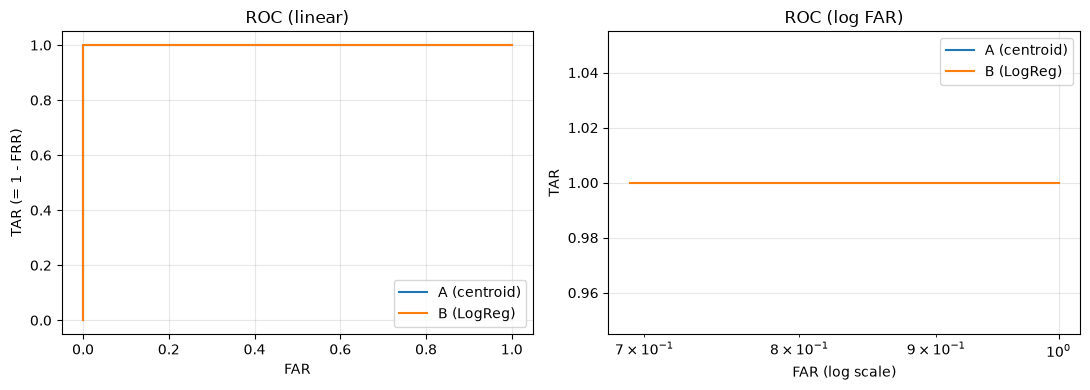

In [28]:
res = {"A (centroid)": summarize(y_va, score_A(X_va)),
       "B (LogReg)": summarize(y_va, score_B(X_va))}
cols = list(next(iter(res.values())))
print(f"{'':<14}" + "".join(f"{c:>16}" for c in cols))
for k, v in res.items():
    print(f"{k:<14}" + "".join(f"{v[c]:>16.4f}" for c in cols))
print(f"\nValidation: {int(y_va.sum())} positives, {int((y_va == 0).sum())} negatives")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name, sc in [("A (centroid)", score_A(X_va)), ("B (LogReg)", score_B(X_va))]:
    fpr, tpr, _ = roc_curve(y_va, sc)
    ax[0].plot(fpr, tpr, label=name)
    m = fpr > 0
    ax[1].semilogx(fpr[m], tpr[m], label=name)
ax[0].set(title="ROC (linear)", xlabel="FAR", ylabel="TAR (= 1 - FRR)")
ax[1].set(title="ROC (log FAR)", xlabel="FAR (log scale)", ylabel="TAR")
for a in ax:
    a.grid(alpha=0.3)
    a.legend()
plt.tight_layout()
plt.show()

## 7) جدول العتبات

لكل عتبة بنشوف الغلطتين مع بعض. هاد الجدول هو اللي بنقرر منه سوا، مو من راسي.

انتبه لعدد الغرباء بـ Validation: لما FAR يكون صغير، عدد الأخطاء الفعلي بيصير رقم أو رقمين، فالتقدير غير ثابت.

Alaa val (positives)   n=  162  min=0.31  p5=0.46  median=0.66  p95=0.82  max=0.85
Alaa test (positives)  n=   56  min=0.53  p5=0.57  median=0.79  p95=0.83  max=0.84
friend1 (strangers)    n=   93  min=-0.03  p5=0.02  median=0.08  p95=0.18  max=0.20
LFW val (strangers)    n= 1639  min=-0.17  p5=-0.09  median=-0.00  p95=0.08  max=0.16
LFW test (strangers)   n= 1580  min=-0.21  p5=-0.09  median=-0.00  p95=0.08  max=0.18

lowest Alaa-val score: 0.31   highest stranger score: 0.20   gap: +0.11

per-video similarity to the train centroid (Alaa):
  alaa_laptop_01   train n= 76  min=0.49  p5=0.62  median=0.79
  alaa_laptop_02   train n= 52  min=0.67  p5=0.69  median=0.80
  alaa_laptop_03   train n= 80  min=0.57  p5=0.61  median=0.74
  alaa_laptop_04   VAL   n= 80  min=0.44  p5=0.47  median=0.59
  alaa_laptop_05   train n= 63  min=0.74  p5=0.77  median=0.84
  alaa_phone_01    VAL   n= 82  min=0.31  p5=0.44  median=0.75
  alaa_phone_02    train n= 70  min=0.53  p5=0.60  median=0.77
  alaa_phone

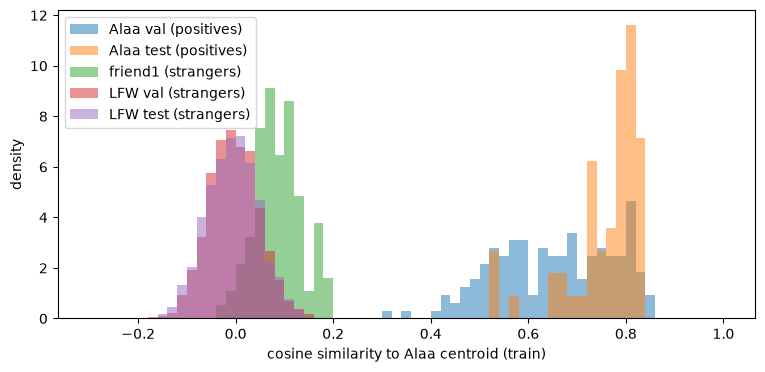

In [29]:
sA_pos_val = score_A(pos_val)
groups = [
    ("Alaa val (positives)", sA_pos_val),
    ("Alaa test (positives)", score_A(pos_test)),
    ("friend1 (strangers)", score_A(others["embeddings"])),
    ("LFW val (strangers)", score_A(neg_val)),
    ("LFW test (strangers)", score_A(neg_test)),
]
for name, s in groups:
    print(f"{name:<22} n={len(s):>5}  min={s.min():.2f}  p5={np.percentile(s, 5):.2f}  "
          f"median={np.median(s):.2f}  p95={np.percentile(s, 95):.2f}  max={s.max():.2f}")

strangers_max = max(groups[2][1].max(), groups[3][1].max(), groups[4][1].max())
print(f"\nlowest Alaa-val score: {sA_pos_val.min():.2f}   highest stranger score: {strangers_max:.2f}   "
      f"gap: {sA_pos_val.min() - strangers_max:+.2f}")

print("\nper-video similarity to the train centroid (Alaa):")
sA_all = score_A(alaa["embeddings"])
for v in sorted(set(alaa_video)):
    m = alaa_video == v
    tag = "VAL" if v in VAL_VIDEOS else "train"
    print(f"  {v:<16} {tag:<5} n={int(m.sum()):>3}  min={sA_all[m].min():.2f}  p5={np.percentile(sA_all[m], 5):.2f}  median={np.median(sA_all[m]):.2f}")

plt.figure(figsize=(9, 4))
bins = np.linspace(-0.3, 1.0, 66)
for name, s in groups:
    plt.hist(s, bins=bins, alpha=0.5, density=True, label=name)
plt.xlabel("cosine similarity to Alaa centroid (train)")
plt.ylabel("density")
plt.legend()
plt.show()

In [30]:
s_pos = score_A(pos_val)                                      # hard Alaa videos (validation)
s_lfw = score_A(np.vstack([lfw_part("train"), neg_val]))      # LFW strangers (A never trained on any negatives)
s_fr = score_A(others["embeddings"])                          # friend1: strangers filmed like Alaa
max_stranger = max(s_lfw.max(), s_fr.max())
print(f"highest stranger score: LFW={s_lfw.max():.2f}  friend1={s_fr.max():.2f}")
print(f"{'thr':>5} {'FRR (val)':>10} {'false accepts LFW':>19} {'false accepts friend1':>22} {'margin':>8}")
for thr in (0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55):
    frr = float((s_pos < thr).mean())
    fa_l = int((s_lfw >= thr).sum()); fa_f = int((s_fr >= thr).sum())
    print(f"{thr:>5.2f} {frr:>10.3f} {fa_l:>8}/{len(s_lfw):<10} {fa_f:>10}/{len(s_fr):<11} {thr - max_stranger:>+8.2f}")

highest stranger score: LFW=0.22  friend1=0.20
  thr  FRR (val)   false accepts LFW  false accepts friend1   margin
 0.25      0.000        0/8686                0/93             +0.03
 0.30      0.000        0/8686                0/93             +0.08
 0.35      0.006        0/8686                0/93             +0.13
 0.40      0.012        0/8686                0/93             +0.18
 0.45      0.043        0/8686                0/93             +0.23
 0.50      0.105        0/8686                0/93             +0.28
 0.55      0.228        0/8686                0/93             +0.33


In [31]:
s_pos_B = score_B(pos_val)
s_neg_B = score_B(neg_val)
print(f"B on validation | Alaa: min={s_pos_B.min():.2f} p5={np.percentile(s_pos_B, 5):.2f} median={np.median(s_pos_B):.2f} "
      f"| LFW strangers: median={np.median(s_neg_B):.2f} max={s_neg_B.max():.2f}")
print(f"Alaa val faces below 0: {int((s_pos_B < 0).sum())}/{len(s_pos_B)}   LFW val strangers at/above 0: {int((s_neg_B >= 0).sum())}/{len(s_neg_B)}")

# Clean in-domain stranger test: retrain WITHOUT friend1, then score friend1
neg_nf = lfw_part("train")
X_nf = np.vstack([pos_train, neg_nf])
y_nf = np.r_[np.ones(len(pos_train)), np.zeros(len(neg_nf))]
clf_nf = LogisticRegression(class_weight="balanced", C=1.0, max_iter=2000).fit(X_nf, y_nf)
s_fr = clf_nf.decision_function(others["embeddings"])
s_pos_nf = clf_nf.decision_function(pos_val)
print(f"\nB trained WITHOUT friend1 | Alaa val: min={s_pos_nf.min():.2f} | friend1: median={np.median(s_fr):.2f} max={s_fr.max():.2f} "
      f"| friend1 faces at/above 0: {int((s_fr >= 0).sum())}/{len(s_fr)}")

B on validation | Alaa: min=-0.48 p5=1.56 median=4.11 | LFW strangers: median=-5.43 max=-3.18
Alaa val faces below 0: 1/162   LFW val strangers at/above 0: 0/1639

B trained WITHOUT friend1 | Alaa val: min=-0.48 | friend1: median=-4.20 max=-2.51 | friend1 faces at/above 0: 0/93


## 8) القرار (تعدّل القيمتين بعد ما نناقش الجدول)

القيم الحالية **مؤقتة**، مو قرار. نختار النموذج (A أو B) ونسبة FAR المقبولة، والعتبة بتنحسب تلقائياً من Validation.

In [32]:
MODEL_CHOICE = "B"      # "A" or "B"   <- fill in our joint decision
THRESHOLD = 0.0        # operating point (for A: cosine similarity)   <- fill in our joint decision
FAR_TARGET = None       # not used anymore (kept because the save cell reads it)

score = score_A if MODEL_CHOICE == "A" else score_B
print(f"model={MODEL_CHOICE}  threshold={THRESHOLD}")
print(f"validation: FRR={(score(pos_val) < THRESHOLD).mean():.3f}   FAR(LFW val)={(score(neg_val) >= THRESHOLD).mean():.4f}")

model=B  threshold=0.0
validation: FRR=0.006   FAR(LFW val)=0.0000


## 9) Test: نجرب مرة وحدة

**لا تعدّل أي شي بعد ما تشوف هالنتيجة** (نموذج، عتبة، فلاتر). لو عدّلت بناءً عليها، الـ Test بيصير Validation ومنخسر الرقم الصادق.

In [33]:
s_te = score(X_te) 
# يحسب درجو وجه كل شخص من وجوه ال test 
pred = s_te >= THRESHOLD
# مصفوفة true or flase نظام قال علاء او لا 
P = y_te == 1
#  هل الوجه فعلا علاء ؟
tp, fn = int((pred & P).sum()), int((~pred & P).sum())
fp, tn = int((pred & ~P).sum()), int((~pred & ~P).sum())
#  تابع اذا علاء حقيقي بس قال مو علاء وهيك للكل 
print(f"TEST  model={MODEL_CHOICE}  threshold={THRESHOLD:.4f}")
print(f"                predicted Alaa   predicted Unknown")
print(f"actual Alaa     {tp:>14}   {fn:>17}   (n={tp + fn})")
print(f"actual stranger {fp:>14}   {tn:>17}   (n={fp + tn})")
print(f"\nFRR = {fn / (tp + fn):.4f}   FAR = {fp / (fp + tn):.4f}   TAR = {tp / (tp + fn):.4f}")
if fp == 0:
    print(f"0 false accepts out of {fp + tn}; 95% upper bound on FAR is roughly {3 / (fp + tn):.4f}")
if fn == 0:
    print(f"0 false rejects out of {tp + fn}; 95% upper bound on FRR is roughly {3 / (tp + fn):.4f}")

TEST  model=B  threshold=0.0000
                predicted Alaa   predicted Unknown
actual Alaa                 56                   0   (n=56)
actual stranger              0                1580   (n=1580)

FRR = 0.0000   FAR = 0.0000   TAR = 1.0000
0 false accepts out of 1580; 95% upper bound on FAR is roughly 0.0019
0 false rejects out of 56; 95% upper bound on FRR is roughly 0.0536


## 10) حفظ النموذج والعتبة

سكربت الكاميرا المباشرة رح يقرأ هالملفات.

In [34]:
joblib.dump(clf, MODELS / "classifier.joblib")
np.save(MODELS / "centroid.npy", centroid)
meta = {
    "model": MODEL_CHOICE,
    "threshold": THRESHOLD,
    "far_target_on_validation": FAR_TARGET,
    "test": {"tp": tp, "fn": fn, "fp": fp, "tn": tn},
    "split": {"val_videos": VAL_VIDEOS, "seed": SEED, "lfw_fractions": LFW_FRACTIONS},
}
(MODELS / "meta.json").write_text(json.dumps(meta, indent=2))
print("saved:", sorted(p.name for p in MODELS.iterdir()))

saved: ['centroid.npy', 'classifier.joblib', 'meta.json']


## حدود لازم تنذكر بالـ README

1. **Test صغير:** جلسة وحدة، فيديو واحد، وإطارات متتالية. الأمثلة المستقلة الفعلية أقل من العدد المكتوب، فالرقم مؤشر مو دليل قاطع.
2. **Domain Gap:** الغرباء بالـ Test (LFW) صور احترافية، مو كاميرا لابتوب. الـ FAR الحقيقي بالتشغيل ممكن يكون أعلى.
3. **friend1** بالـ Train بس، فما في اختبار على غريب بكاميرا لابتوب إلا الاختبار الحي.
4. العتبة اتحسبت على Validation والنموذج متدرب على Train بس (ما أعدنا التدريب على Train + Validation).
5. ترخيص أوزان InsightFace: للبحث وغير تجاري.